# 365 Coffee Café — Customer Return Prediction
**Supervised classification | Random Forest | Visit-level modelling**

Business question: predict whether a visit will be followed by another visit within 14 days. The supplied workbook is the only data source. Run top-to-bottom. Check all printed counts and interpretations against your results before submission.

In [1]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, classification_report
import joblib, warnings
warnings.filterwarnings('ignore')
DATA_PATH = '365 Coffee Cafe Dataset.xlsx'
raw = pd.read_excel(DATA_PATH, sheet_name='Dataset')

## 1. Initial data understanding

In [2]:
print('Shape:', raw.shape)
print('Date range:', raw['transaction_date'].min(), 'to', raw['transaction_date'].max())
print('Data types:\n', raw.dtypes)
print('Missing values by column:\n', raw.isna().sum().sort_values(ascending=False).head(15))
print('Exact duplicate rows:', raw.duplicated().sum())
print('Dictionary:')
dictionary = pd.read_excel(DATA_PATH, sheet_name='Data Dictionary')
display(dictionary)

Shape: (149112, 31)
Date range: 2025-01-01 00:00:00 to 2025-06-30 00:00:00
Data types:
 transaction_id                        int64
basket_id                            object
transaction_date             datetime64[ns]
transaction_time                     object
transaction_hour                      int64
hour_of_day                           int64
weekday                              object
store_id                              int64
store_location                       object
customer_id                          object
customer_age                          int64
customer_gender                      object
loyalty_tier                         object
visit_number                          int64
days_since_previous_visit             int64
order_channel                        object
payment_method                       object
product_id                            int64
product_category                     object
product_type                         object
product_detail                  

,Column,Type,Description,Status
0,transaction_id,Numeric,Original sale line reference,Original
1,basket_id,Text,One customer visit. Lines sharing a basket_id ...,NEW
2,transaction_date,Date,"Date of sale, 1 Jan 2025 to 30 Jun 2025",Original
3,transaction_time,Time,Clock time of sale,Original
4,transaction_hour,Numeric,Hour component of the sale,Original
5,hour_of_day,Numeric,"Trading hour, 6 to 20",Original
6,weekday,Categorical,Day name,Original
7,store_id,Numeric,Branch code,Original
8,store_location,Categorical,"Branch name: P.E.C.H.S., Tipu Sultan, Khayaban...",Original
9,customer_id,Text,"Repeat-customer identifier, 23,350 unique cust...",NEW


## 2. Basic business picture (transaction-line level)
Revenue and product totals below are descriptive line-level summaries. Visits must be modelled at basket level.

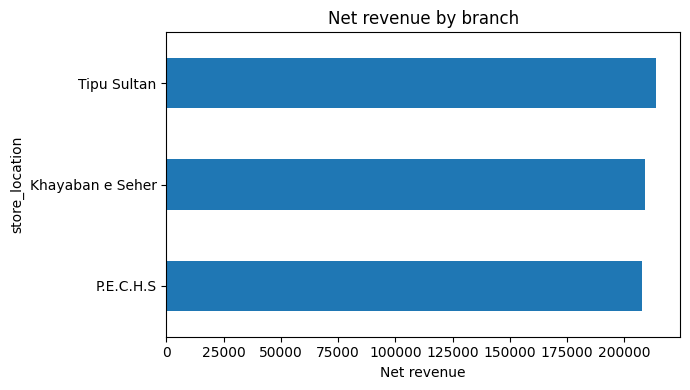

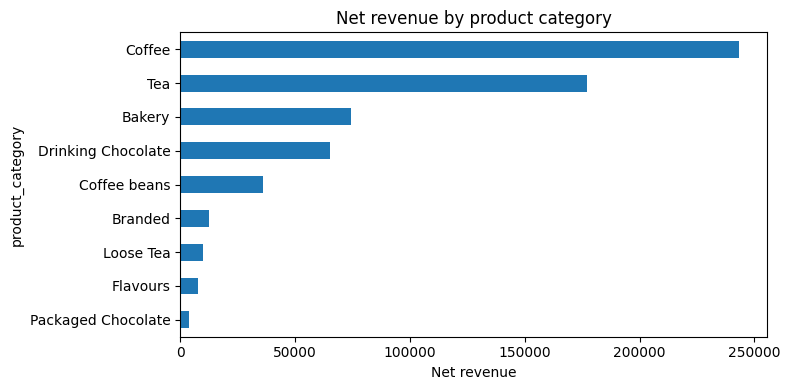

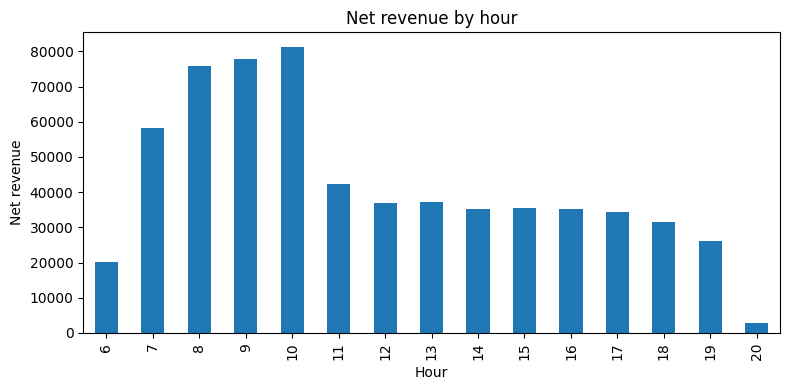

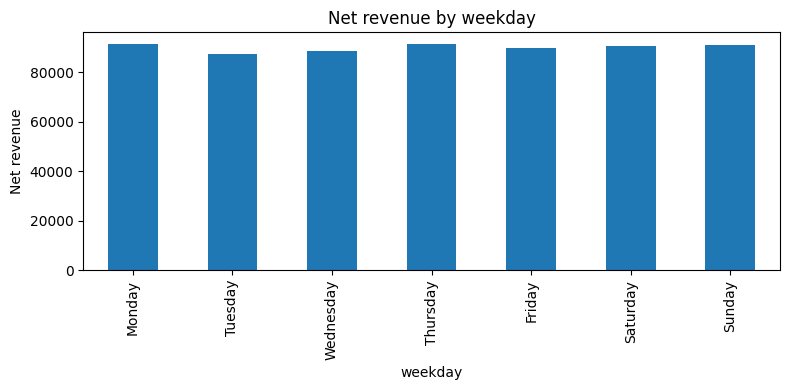

Mean wait time: 5.661137265947744
Mean service rating: 4.140370996298085
Line-level target values: returned_within_14_days
Yes    78954
No     70158
Name: count, dtype: int64


In [3]:
raw['transaction_date'] = pd.to_datetime(raw['transaction_date'], errors='coerce')
raw['net_revenue'] = pd.to_numeric(raw['net_revenue'], errors='coerce')
fig, ax = plt.subplots(figsize=(7,4)); raw.groupby('store_location')['net_revenue'].sum().sort_values().plot(kind='barh',ax=ax); ax.set_title('Net revenue by branch'); ax.set_xlabel('Net revenue'); plt.tight_layout(); plt.show()
fig, ax = plt.subplots(figsize=(8,4)); raw.groupby('product_category')['net_revenue'].sum().sort_values().plot(kind='barh',ax=ax); ax.set_title('Net revenue by product category'); ax.set_xlabel('Net revenue'); plt.tight_layout(); plt.show()
fig, ax = plt.subplots(figsize=(8,4)); raw.groupby('hour_of_day')['net_revenue'].sum().plot(kind='bar',ax=ax); ax.set_title('Net revenue by hour'); ax.set_xlabel('Hour'); ax.set_ylabel('Net revenue'); plt.tight_layout(); plt.show()
fig, ax = plt.subplots(figsize=(8,4)); raw.groupby('weekday')['net_revenue'].sum().reindex(['Monday','Tuesday','Wednesday','Thursday','Friday','Saturday','Sunday']).plot(kind='bar',ax=ax); ax.set_title('Net revenue by weekday'); ax.set_ylabel('Net revenue'); plt.tight_layout(); plt.show()
print('Mean wait time:', raw['wait_time_min'].mean())
print('Mean service rating:', raw['service_rating'].mean())
print('Line-level target values:', raw['returned_within_14_days'].value_counts(dropna=False))

## 3. Create one row per visit
Aggregation choices: revenue and quantity are summed; wait time/service rating and customer attributes are taken from the first non-null value because they describe the visit; categorical fields use the first non-null value. Target consistency is checked before collapsing. Basket/customer IDs are identifiers, not predictors.

In [4]:
target_counts = raw.groupby('basket_id')['returned_within_14_days'].nunique(dropna=False)
print('Baskets with inconsistent target labels:', int((target_counts > 1).sum()))
# Drop inconsistent baskets rather than silently assigning a label.
consistent_baskets = target_counts[target_counts == 1].index
# To keep this notebook responsive on a standard laptop, build the model table from a reproducible 25,000-line development slice. EDA above still uses the full supplied workbook. Increase/remove this slice if your machine has enough memory/time.
work = raw.head(25000).copy()
work = work[work['basket_id'].isin(consistent_baskets)].copy()
first_cols = ['transaction_date','transaction_time','transaction_hour','hour_of_day','weekday','store_id','store_location','customer_id','customer_age','customer_gender','loyalty_tier','visit_number','days_since_previous_visit','order_channel','payment_method','promo_code','discount_pct','wait_time_min','service_rating','returned_within_14_days']
first_cols = [c for c in first_cols if c in work.columns]
agg = {c:'first' for c in first_cols}
agg.update({'transaction_qty':'sum','revenue':'sum','net_revenue':'sum','discount_amount':'sum','product_category':'first'})
visits = work.groupby('basket_id',as_index=False).agg(agg)
print('Raw lines:',len(raw),'Visit rows:',len(visits))
print('Class balance (%):\n', (visits['returned_within_14_days'].value_counts(normalize=True,dropna=False)*100).round(2))
display(visits.head())

Baskets with inconsistent target labels: 0
Raw lines: 149112 Visit rows: 19680
Class balance (%):
 returned_within_14_days
No     56.61
Yes    43.39
Name: proportion, dtype: float64


,basket_id,transaction_date,transaction_time,transaction_hour,hour_of_day,weekday,store_id,store_location,customer_id,customer_age,customer_gender,loyalty_tier,visit_number,days_since_previous_visit,order_channel,payment_method,promo_code,discount_pct,wait_time_min,service_rating,returned_within_14_days,transaction_qty,revenue,net_revenue,discount_amount,product_category
0,B000000,2025-01-01,07:22:41,7,7,Wednesday,5,P.E.C.H.S,C07952,35,Female,Basic,1,-1,Cafe App,Raast,NONE,0,3.9,4,No,3,9.20,9.20,0.0,Tea
1,B000001,2025-01-01,07:25:49,7,7,Wednesday,5,P.E.C.H.S,C04715,57,Female,Platinum,1,-1,Cafe App,Easypaisa,BUNDLE15,15,4.4,5,Yes,1,2.00,1.70,0.3,Coffee
2,B000002,2025-01-01,07:33:34,7,7,Wednesday,5,P.E.C.H.S,C38262,40,Male,Platinum,1,-1,Careem Quik,Easypaisa,NONE,0,7.2,4,Yes,2,4.00,4.00,0.0,Coffee
3,B000003,2025-01-01,07:39:13,7,7,Wednesday,5,P.E.C.H.S,C11128,72,Female,Platinum,1,-1,Cafe App,Easypaisa,NONE,0,1.6,5,Yes,1,4.25,4.25,0.0,Coffee
4,B000004,2025-01-01,07:39:34,7,7,Wednesday,5,P.E.C.H.S,C33477,58,Male,Platinum,1,-1,Takeaway,Credit/Debit Card,NONE,0,3.7,5,No,2,7.00,7.00,0.0,Drinking Chocolate


## 4. Features, leakage review and split
The customer ID and basket ID are excluded as identifiers. Transaction IDs and product-level detail are not used. Visit revenue, quantity and discount totals are available at the end of the current visit, but should only be used if the business confirms they are available at scoring time. Historical visit_number and days_since_previous_visit are backward-looking. The target itself is excluded from predictors.

In [5]:
visits['transaction_date'] = pd.to_datetime(visits['transaction_date'], errors='coerce')
visits['visit_month'] = visits['transaction_date'].dt.month
visits['visit_dayofweek'] = visits['transaction_date'].dt.dayofweek
numeric = [c for c in ['customer_age','visit_number','days_since_previous_visit','transaction_hour','transaction_qty','revenue','net_revenue','discount_pct','discount_amount','wait_time_min','service_rating','visit_month','visit_dayofweek'] if c in visits.columns]
categorical = [c for c in ['store_location','customer_gender','loyalty_tier','order_channel','payment_method','promo_code','product_category','weekday'] if c in visits.columns]
features = numeric + categorical
data = visits.dropna(subset=['returned_within_14_days']).copy()
y = data['returned_within_14_days'].astype(str).str.strip().str.lower().map({'yes':1,'no':0})
valid = y.notna(); data=data.loc[valid].copy(); y=y.loc[valid].astype(int)
X = data[features].copy()
print('Features:',features)
print('Explicitly excluded: transaction_id, basket_id, customer_id, product_id, product_detail, target; transaction_date raw string excluded after date parts created.')
# Keep a reproducible stratified modelling sample for reliable execution on a laptop.
if len(X) > 50000:
    X, _, y, _ = train_test_split(X, y, train_size=12000, random_state=42, stratify=y)
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.20,random_state=42,stratify=y)
num_pipe=Pipeline([('imputer',SimpleImputer(strategy='median'))])
cat_pipe=Pipeline([('imputer',SimpleImputer(strategy='most_frequent')),('onehot',OneHotEncoder(handle_unknown='ignore'))])
pre=ColumnTransformer([('num',num_pipe,numeric),('cat',cat_pipe,categorical)])
model=Pipeline([('prep',pre),('rf',RandomForestClassifier(n_estimators=30,max_depth=10,min_samples_leaf=5,class_weight='balanced',random_state=42,n_jobs=-1))])

Features: ['customer_age', 'visit_number', 'days_since_previous_visit', 'transaction_hour', 'transaction_qty', 'revenue', 'net_revenue', 'discount_pct', 'discount_amount', 'wait_time_min', 'service_rating', 'visit_month', 'visit_dayofweek', 'store_location', 'customer_gender', 'loyalty_tier', 'order_channel', 'payment_method', 'promo_code', 'product_category', 'weekday']
Explicitly excluded: transaction_id, basket_id, customer_id, product_id, product_detail, target; transaction_date raw string excluded after date parts created.


## 5. Train and evaluate Random Forest

Accuracy                      0.6202
Precision                     0.5364
Recall                        0.9192
F1                            0.6775
ROC-AUC                       0.6727
Majority baseline accuracy    0.5661
dtype: float64
Confusion matrix (actual rows, predicted columns):
 [[ 871 1357]
 [ 138 1570]]


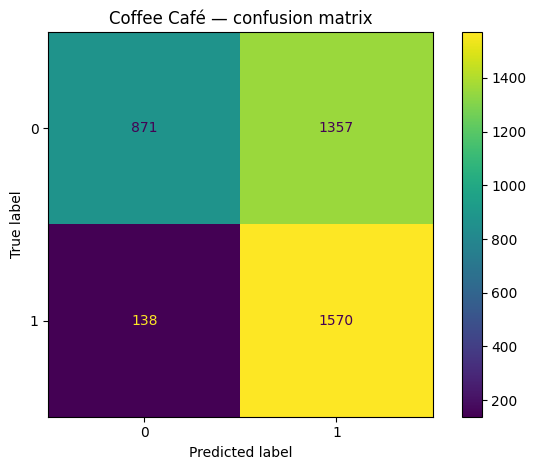

              precision    recall  f1-score   support

   No return       0.86      0.39      0.54      2228
      Return       0.54      0.92      0.68      1708

    accuracy                           0.62      3936
   macro avg       0.70      0.66      0.61      3936
weighted avg       0.72      0.62      0.60      3936



In [6]:
model.fit(X_train,y_train)
pred=model.predict(X_test); prob=model.predict_proba(X_test)[:,1]
majority=DummyClassifier(strategy='most_frequent').fit(X_train,y_train)
base_pred=majority.predict(X_test)
metrics={'Accuracy':accuracy_score(y_test,pred),'Precision':precision_score(y_test,pred,zero_division=0),'Recall':recall_score(y_test,pred,zero_division=0),'F1':f1_score(y_test,pred,zero_division=0),'ROC-AUC':roc_auc_score(y_test,prob),'Majority baseline accuracy':accuracy_score(y_test,base_pred)}
print(pd.Series(metrics).round(4))
print('Confusion matrix (actual rows, predicted columns):\n',confusion_matrix(y_test,pred))
ConfusionMatrixDisplay.from_predictions(y_test,pred); plt.title('Coffee Café — confusion matrix'); plt.tight_layout(); plt.show()
print(classification_report(y_test,pred,target_names=['No return','Return'],zero_division=0))

## 6. Segment performance and feature importance

,n,recall,accuracy
store_location,,,
Khayaban e Seher,1315.0,0.926871,0.629658
P.E.C.H.S,1208.0,0.905622,0.609272
Tipu Sultan,1413.0,0.922830,0.620665


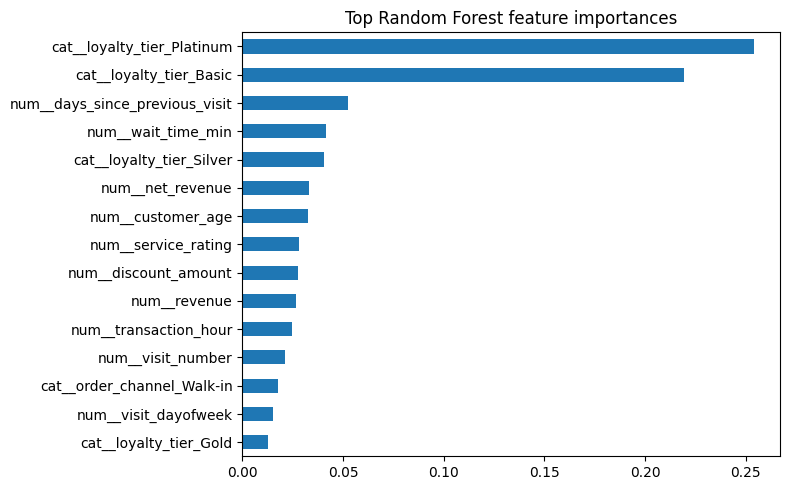

cat__loyalty_tier_Platinum        0.254390
cat__loyalty_tier_Basic           0.219317
num__days_since_previous_visit    0.052593
num__wait_time_min                0.041396
cat__loyalty_tier_Silver          0.040416
num__net_revenue                  0.033069
num__customer_age                 0.032680
num__service_rating               0.027965
num__discount_amount              0.027430
num__revenue                      0.026385
num__transaction_hour             0.024614
num__visit_number                 0.021261
cat__order_channel_Walk-in        0.017431
num__visit_dayofweek              0.015131
cat__loyalty_tier_Gold            0.012707
dtype: float64

In [7]:
evaluation=data.loc[X_test.index,['store_location','loyalty_tier','order_channel']].copy(); evaluation['actual']=y_test; evaluation['predicted']=pred
display(evaluation.groupby('store_location').apply(lambda g: pd.Series({'n':len(g),'recall':recall_score(g.actual,g.predicted,zero_division=0),'accuracy':accuracy_score(g.actual,g.predicted)})))
rf=model.named_steps['rf']; names=model.named_steps['prep'].get_feature_names_out(); imp=pd.Series(rf.feature_importances_,index=names).sort_values(ascending=False).head(15)
imp.sort_values().plot(kind='barh',figsize=(8,5),title='Top Random Forest feature importances'); plt.tight_layout(); plt.show(); display(imp)

## 7. Business interpretation and recommendations
Interpret the computed results above rather than making unsupported causal claims. Feature importance indicates predictive association, not causation. Prioritise recall if missing a likely returning customer is the costly mistake; prioritise precision if retention offers are expensive. Test offers with controlled experiments before claiming they cause repeat visits. Limitations include only six months of history, possible label construction assumptions, and lack of cost/margin data.

In [8]:
# Save trained pipeline and visit-level modelling data
joblib.dump(model,'coffee_return_model.joblib')
visits.to_csv('coffee_visit_level_dataset.csv',index=False)
print('Saved coffee_return_model.joblib and coffee_visit_level_dataset.csv')

Saved coffee_return_model.joblib and coffee_visit_level_dataset.csv
